# First buckling of blade-stiffened CFRP curved panels under axial compression (Abramovich and Weller 2009)

Abramovich and Weller [1] collect the tests of the POSICOSS project on curved graphite-epoxy panels
stiffened by co-cured stringers. The nine panels PSC1 to PSC9, with blade stringers, were first reported
in Abramovich et al. [2], which gives the stringer lay-up, the drawing of the panels and the first
buckling loads of a finite element model (MSC/NASTRAN). They form three groups of three nominally
identical panels: five blades 20 mm high (PSC1, PSC2, PSC4), five blades 15 mm high (PSC3, PSC5, PSC6)
and six blades 20 mm high (PSC7 to PSC9).

This notebook builds the three groups with `panels.multidomain.MultiDomain`, every part being a
`panels.shell.Shell` domain: curved skin strips, the stepped feet as cylindrical shells bonded to the
skin and the blades as flat plates, connected along their edges and over the bonded areas. It computes the first buckling load under axial compression with linear
buckling analyses, shows the convergence and the mode shapes, and compares the loads with the finite
element values of [2] and with the tests of [1, 2].

**References**

1. Abramovich, H., and Weller, T., "Buckling and postbuckling behavior of laminated composite stringer
   stiffened curved panels under axial compression: experiments and design guidelines", Journal of
   Mechanics of Materials and Structures, 4(7-8), 1187-1207, 2009.
   <https://doi.org/10.2140/jomms.2009.4.1187>
2. Abramovich, H., Grunwald, A., Pevsner, P., Weller, T., et al., "Experiments on axial compression
   postbuckling behavior of stiffened cylindrical composite panels", 44th AIAA/ASME/ASCE/AHS/ASC
   Structures, Structural Dynamics, and Materials Conference, Norfolk, Virginia, 2003, AIAA 2003-1793.
   <https://doi.org/10.2514/6.2003-1793>
3. Castro, S. G. P., and Donadon, M. V., "Assembly of semi-analytical models to address linear buckling
   and vibration of stiffened composite panels with debonding defect", Composite Structures, 160,
   232-247, 2017. <https://doi.org/10.1016/j.compstruct.2016.10.026>

The analyses take about 95 minutes on one core; the notebook is stored with the outputs of its last execution.

In [1]:
import time

import numpy as np
import matplotlib.pyplot as plt

import composites
import panels

import posicoss_utils as pu
from posicoss_utils import print_table, rel

%matplotlib inline
print('panels', panels.__version__,
      '| composites', composites.__version__)
T_START = time.time()

panels 0.15.0 | composites 0.10.3


## 1. Data of the panels

| quantity | value | source |
|---|---|---|
| material | Hexcel IM7/8552 graphite-epoxy, co-cured | [1] p. 1189; [2] p. 1 |
| lamina | $E_{11}$ = 147300 N/mm², $E_{22}$ = 11800 N/mm², $G_{12}$ = 6000 N/mm², $\nu_{12}$ = 0.3 | [1] Table 1 (properties used in the calculations of the AXIAL panels, of the same material) |
| ply thickness | 0.125 mm | [1] p. 1189; [2] p. 2 |
| radius | $R$ = 938 mm | [1] p. 1189; [2] p. 2 |
| length | 720 mm in total, with two end loading pieces 30 mm high; 660 mm between them | [1] p. 1189; [2] Fig. 1c (30.0 / 660.0 / 30.0) |
| arc length | 680 mm | [1] p. 1189; [2] Fig. 1c |
| skin | (0, ±45, 90)$_S$ | [1] p. 1189; [2] p. 2 |
| stringers | (±45, 0$_2$)$_{3S}$, 24 plies, 3 mm | [2] p. 2; thickness 3 mm in [1] Fig. 1 (top) |
| stringer positions, 5 blades | 4 equal spaces over 544.0 mm, 68.0 mm from the edges | [2] Fig. 1c, section A-A for ASSY 501, 502 |
| stringer positions, 6 blades | 5 equal spaces over 566.7 mm, 56.7 mm from the edges | [2] Fig. 1c, section A-A for ASSY 503 |
| blade height $h_s$ | 20 mm (PSC1, 2, 4, 7, 8, 9) or 15 mm (PSC3, 5, 6) | [1] Table 3; [2] Table 1 |
| section | T made of two L's back to back: a blade 3 mm thick on the inner side of the skin, the tip 21 mm from the outer face of the 1 mm skin; a foot 60 mm wide in three steps, 20, 40 and 60 mm wide, where skin and foot are 2.5, 2.0 and 1.5 mm thick; fillet radius 2 mm | [1] Fig. 1 (top) |

The stringers are on the concave side ([2], Fig. 1a and b; the scanned "outer non-stiffened curved
surface", p. 2). The tip at 21 mm from the outer face of the 1 mm skin is 20 mm from its inner face,
which is the $h_s$ of [1], Table 3.

Not given, and assumed here:

* **the plies of the foot steps.** Each half of the blade laminate, (±45, 0$_2$)$_3$, 12 plies and 1.5
  mm, turns into one half of the foot; which plies end at the steps of 1.0 and 0.5 mm is not given in
  [1] or [2]. Three schemes are computed (Section 7): whole repeats of [45/-45/0/0] dropped (2 and 1
  repeats left, the model of Sections 2 to 6), the 0° plies dropped first, and the ±45° plies dropped
  first.
* **the section of the 15 mm blades**, taken equal to that of Fig. 1 of [1] with the blade 5 mm shorter.
* **the support of the unloaded edges.** The panels were tested with "longitudinal fixture plates" on
  the unloaded edges ([2], Fig. 4); [1] calls these edges "supported" (p. 1189). Here they have $w = 0$
  with $u$, $v$ and the rotation free; clamped edges give the same first buckling load (Section 7).
* $G_{13}$ and $G_{23}$, which do not enter the classical laminated plate theory used here.

The reference values are the first buckling loads, in kN:

| group | blades | $h_s$ (mm) | MSC/NASTRAN [2] Table 1 | tests [1] Table 3, [2] Table 1 |
|---|---|---|---|---|
| A | 5 | 20 | 92 | PSC1 131.0, PSC2 150.0, PSC4 158.5 |
| B | 5 | 15 | 89 | PSC3 136.0, PSC5 113.0, PSC6 126.0 |
| C | 6 | 20 | 139 | PSC7 228.5, PSC8 240.0, PSC9 244.0 |

In [2]:
# lamina, [1] Table 1; G13 and G23 (not given) do not enter the CLPT
E11, E22, G12, NU12 = 147300., 11800., 6000., 0.3     # N/mm^2
PLYT = 0.125                                          # mm
LAMINAPROP = (E11, E22, NU12, G12, G12, G12)

R_SKIN = 938.        # mm, [1] p. 1189
L_FREE = 660.        # mm, [2] Fig. 1c
ARC = 680.           # mm, [1] p. 1189
SKIN = [0, 45, -45, 90, 90, -45, 45, 0]   # (0, +-45, 90)_S
HALF = [45, -45, 0, 0]*3                  # (+-45, 0_2)_3
BLADE = HALF + HALF[::-1]                 # (+-45, 0_2)_3S, [2] p. 2
# steps of each half of the foot, from the blade outwards: 10 mm wide, 1.5,
# 1.0 and 0.5 mm thick, [1] Fig. 1; plies from the inner face of the foot to
# the face bonded to the skin. The plies that end at the steps are not given:
# three schemes (Section 7)
UNIT = [45, -45, 0, 0]
PLY_DROPS = {
    'repeats [45/-45/0/0] dropped': [UNIT*3, UNIT*2, UNIT],
    '0 deg plies dropped first': [UNIT*3, [45, -45, 45, -45, 0, 0, 45, -45],
                                  [45, -45, 45, -45]],
    '+-45 deg plies dropped first': [UNIT*3, [45, -45, 0, 0, 0, 0, 0, 0],
                                     [0, 0, 0, 0]],
}
for name, stacks in PLY_DROPS.items():
    print('%-30s' % name, ' | '.join('/'.join('%d' % a for a in st) for st in stacks))
FEET = [(10., stack) for stack in PLY_DROPS['repeats [45/-45/0/0] dropped']]
T_FOOT_CENTRE = len(FEET[0][1])*PLYT

GROUPS = {
    'A': dict(panels='PSC1, PSC2, PSC4', ys=[68. + 136.*k for k in range(5)], hs=20.,
              nastran=92., tests={'PSC1': 131.0, 'PSC2': 150.0, 'PSC4': 158.5}),
    'B': dict(panels='PSC3, PSC5, PSC6', ys=[68. + 136.*k for k in range(5)], hs=15.,
              nastran=89., tests={'PSC3': 136.0, 'PSC5': 113.0, 'PSC6': 126.0}),
    'C': dict(panels='PSC7, PSC8, PSC9', ys=[56.7 + 566.7/5*k for k in range(6)], hs=20.,
              nastran=139., tests={'PSC7': 228.5, 'PSC8': 240.0, 'PSC9': 244.0}),
}
for g, d in GROUPS.items():
    print('group %s: stringers at %s mm; blade domain %.2f mm wide'
          % (g, ', '.join('%.1f' % y for y in d['ys']), d['hs'] - T_FOOT_CENTRE/2))

repeats [45/-45/0/0] dropped   45/-45/0/0/45/-45/0/0/45/-45/0/0 | 45/-45/0/0/45/-45/0/0 | 45/-45/0/0
0 deg plies dropped first      45/-45/0/0/45/-45/0/0/45/-45/0/0 | 45/-45/45/-45/0/0/45/-45 | 45/-45/45/-45
+-45 deg plies dropped first   45/-45/0/0/45/-45/0/0/45/-45/0/0 | 45/-45/0/0/0/0/0/0 | 0/0/0/0
group A: stringers at 68.0, 204.0, 340.0, 476.0, 612.0 mm; blade domain 19.25 mm wide
group B: stringers at 68.0, 204.0, 340.0, 476.0, 612.0 mm; blade domain 14.25 mm wide
group C: stringers at 56.7, 170.0, 283.4, 396.7, 510.1, 623.4 mm; blade domain 19.25 mm wide


## 2. The model

The skin is split along the arc into curved domains (`cylshell_clpt_sanders`): the bays between the
feet and one strip under each step of each half-foot, six strips per stringer. Consecutive skin domains
are joined with the connection `'SSycte'` (continuous $u$, $v$, $w$ and slope). Each stringer is
assembled from a cylindrical shell, the foot, and a plate, the blade:

* the **foot**: six cylindrical-shell domains (`cylshell_clpt_sanders`), one per step, each with its own
  laminate, bonded with `'SB'` to the inner face of the skin strip under it (the displacements of the two
  faces in contact are equal over the whole area [3]). The offsets of their laminates give all of them
  the same reference surface, the mid-surface of the central step, with the plies of every step on the
  inner face of the skin. The steps are not connected to each other: the bond makes each of them follow
  the skin, which is continuous. (Domains of different thickness joined with `'SSycte'` at their own
  mid-surfaces would also have their slope $w_{,x}$ tied to zero along the steps.)
* the **blade**: a flat plate standing on the reference surface of the central foot domains at the
  mid-plane of the stringer and pointing inwards, connected with `'BFycte'`, which makes the
  displacements and the rotation about the common edge continuous. The blade is loaded in its own
  plane, and its bending in that plane, the bending of the stringer normal to the skin, is destabilised
  by the axial force through the term $N_{xx} v_{,x}^2$ of the Green-Lagrange strains, which the von
  Kármán strains do not have: the blade is a `plate_clpt_gl` plate.

The blade domain is $h_s - 0.75$ mm wide (printed above); the 2 mm fillets are not modelled. All
connections are imposed exactly with the null-space method of `MultiDomain` (`conn_method='null-space'`).

The bfsccylinder implementation of this case makes the same modelling choice, with finite elements: the
foot is made of cylindrical-shell elements on the nodes of the skin, with an offset laminate, and the
blade of flat plate elements; its blade is tied to the mid-surface of the skin, the only reference
surface of the elements there. That variant is computed in Section 7.

**Boundary conditions.** The loaded edges are held in the end loading pieces: at $x = 0$ all domains
have $u = v = w = w_{,x} = 0$; at $x = L$ they have $v = w = w_{,x} = 0$, and the skin and the blades
the uniform end-shortening $u = -\delta$, imposed exactly (`pd_method='null-space'`), the feet following
the skin through `'SB'`. The unloaded edges $y = 0$ and $y = 680$ mm have $w = 0$.

In [3]:
def build(group, m, n_bay, n_strip=4, n_blade=6, feet=FEET, L=L_FREE,
          unloaded='ss', foot_reference='foot', blade_model='plate_clpt_gl'):
    d = GROUPS[group]
    if feet and foot_reference == 'foot':
        # blade root on the mid-surface of the central step of the foot
        width = d['hs'] - len(feet[0][1])*PLYT/2
    else:
        # blade root on the mid-surface of the skin
        width = d['hs'] + len(SKIN)*PLYT/2
    return pu.blade_panel(R_SKIN, L, ARC, d['ys'], SKIN, BLADE, width, feet,
                          PLYT, LAMINAPROP, m=m, n_bay=n_bay, n_strip=n_strip,
                          n_blade=n_blade, unloaded=unloaded,
                          foot_reference=foot_reference,
                          blade_model=blade_model)


def solve(group, m, n_bay, num_eigvalues=4, **kwargs):
    """Linear buckling; first buckling load in kN and pre-buckling axial
    stiffness in kN/mm"""
    md, parts = build(group, m, n_bay, **kwargs)
    ev, evec, c1, P1, sec = pu.linear_buckling(md, num_eigvalues)
    # end-shortening of 1 mm at load factor 1: P1 is the axial force in N
    return dict(md=md, parts=parts, ev=ev, evec=evec, c1=c1,
                crit=ev[0]*P1/1e3, stiff=P1/1e3, size=md.get_size(), sec=sec)


for g in GROUPS:
    md_, parts_ = build(g, 10, 8)
    print('group %s: %d skin, %d foot and %d blade domains; Ritz constants for m = 10: %d'
          % (g, len(parts_['skins']), len(parts_['feet']), len(parts_['blades']),
             md_.get_size()))

group A: 36 skin, 30 foot and 5 blade domains; Ritz constants for m = 10: 9300
group B: 36 skin, 30 foot and 5 blade domains; Ritz constants for m = 10: 9300
group C: 43 skin, 36 foot and 6 blade domains; Ritz constants for m = 10: 11160


## 3. Linear buckling about the linear pre-buckling state

Each field of each domain is a Ritz series of products of Bardell's hierarchical functions along $x$ and
$y$ [3]. The connections and the supports are linear constraints on the Ritz constants $\boldsymbol{c}$ of
the assembly; with the end-shortening prescribed as $\lambda \delta$, every admissible configuration is
$\boldsymbol{c} = \boldsymbol{Z} \boldsymbol{c}_r + \lambda \boldsymbol{c}_{p}$, with $\boldsymbol{Z}$ a
basis of the null space of the constraints and $\boldsymbol{c}_p$ a particular solution. The linear
static solution for $\lambda = 1$, $\boldsymbol{c}_1$, is the pre-buckling state, and the critical load
factors $\lambda$ solve

$$\left(\boldsymbol{K}_r + \lambda \boldsymbol{K}_{G r}(\boldsymbol{c}_1)\right)\boldsymbol{\phi}_r = \boldsymbol{0}$$

with the reduced constitutive and geometric stiffness matrices, `MultiDomain.linear_buckling`. The axial
force at $\lambda = 1$ is the reaction work-conjugate to the end-shortening $\delta$ = 1 mm,
$P_1 = \boldsymbol{c}_p^\top \boldsymbol{r}(\boldsymbol{c}_1)$ (`MultiDomain.reaction_pd`), and the first
buckling load is $\lambda_1 P_1$. The pre-buckling state is that of the clamped curved panel, with the
bending near the loaded edges due to the restrained Poisson expansion.

## 4. Convergence

The numbers of terms along the axis, $m$, and across the widest bay, $n$, are increased together (the
narrower bays get proportionally fewer terms, at least 4); the strips of the feet (4 terms) and the
blades (6 terms) are checked with a last row of more terms. The load must change by less than 1 %
between the last two meshes.

In [4]:
MESHES = [(12, 8), (16, 10), (20, 12), (24, 12), (28, 14)]
conv = {}
for g in GROUPS:
    rows = []
    prev = None
    for m, n in MESHES:
        res = solve(g, m, n)
        conv[(g, m, n)] = res
        change = '' if prev is None else '%+.2f' % rel(res['crit'], prev)
        rows.append([m, n, res['size'], '%.2f' % res['crit'], change,
                     '%.1f' % res['stiff'], '%.0f' % res['sec']])
        prev = res['crit']
    m, n = MESHES[-2]
    res = solve(g, m, n, n_strip=6, n_blade=8)
    rows.append(['%d (feet 6, blades 8)' % m, n, res['size'], '%.2f' % res['crit'],
                 '%+.3f vs same m, n' % rel(res['crit'], conv[(g, m, n)]['crit']),
                 '%.1f' % res['stiff'], '%.0f' % res['sec']])
    print('\ngroup %s (%s)' % (g, GROUPS[g]['panels']))
    print_table(rows, ['m', 'n (widest bay)', 'Ritz constants', 'first buckling (kN)',
                       'change %', 'stiffness (kN/mm)', 's'])


group A (PSC1, PSC2, PSC4)
                    m  n (widest bay)  Ritz constants  first buckling (kN)             change %  stiffness (kN/mm)    s
---------------------  --------------  --------------  -------------------  -------------------  -----------------  ---
                   12               8           11160               116.52                                   136.9    9
                   16              10           15360               101.20               -13.15              136.8   20
                   20              12           19800                97.11                -4.04              136.8   50
                   24              12           23760                96.84                -0.28              136.8  102
                   28              14           28560                96.84                -0.00              136.8  275
24 (feet 6, blades 8)              12           33120                96.84  -0.002 vs same m, n              136.8  538



group B (PSC3, PSC5, PSC6)
                    m  n (widest bay)  Ritz constants  first buckling (kN)             change %  stiffness (kN/mm)    s
---------------------  --------------  --------------  -------------------  -------------------  -----------------  ---
                   12               8           11160               108.60                                   127.1    7
                   16              10           15360                94.37               -13.11              127.1   18
                   20              12           19800                90.56                -4.03              127.1   48
                   24              12           23760                90.32                -0.28              127.1  122
                   28              14           28560                90.31                -0.00              127.1  274
24 (feet 6, blades 8)              12           33120                90.31  -0.002 vs same m, n              127.1  641



group C (PSC7, PSC8, PSC9)
                    m  n (widest bay)  Ritz constants  first buckling (kN)             change %  stiffness (kN/mm)    s
---------------------  --------------  --------------  -------------------  -------------------  -----------------  ---
                   12               8           13392               170.73                                   152.4   11
                   16              10           18432               152.60               -10.62              152.3   26
                   20              12           23760               147.48                -3.35              152.3   66
                   24              12           28512               146.25                -0.84              152.2  120
                   28              14           34272               146.23                -0.01              152.2  334
24 (feet 6, blades 8)              12           39744               146.24  -0.008 vs same m, n              152.2  738


## 5. Results and comparison with the reference values

The finest mesh of Section 4 gives the first buckling loads below, compared with the finite element
values of [2] and with each test.

In [5]:
M_FIN, N_FIN = MESHES[-1]
rows = []
for g, d in GROUPS.items():
    p = conv[(g, M_FIN, N_FIN)]['crit']
    rows.append([g, d['panels'], '%.1f' % p, '%.0f' % d['nastran'],
                 '%+.1f' % rel(p, d['nastran']), '', ''])
    for name, test in d['tests'].items():
        rows.append(['', '', '', '', '', '%s %.1f' % (name, test), '%+.1f' % rel(p, test)])
print('m = %d, n = %d' % (M_FIN, N_FIN))
print_table(rows, ['group', 'panels', 'panels (kN)', 'MSC/NASTRAN [2] (kN)',
                   'difference %', 'test (kN)', 'difference %'])

m = 28, n = 14
group            panels  panels (kN)  MSC/NASTRAN [2] (kN)  difference %   test (kN)  difference %
-----  ----------------  -----------  --------------------  ------------  ----------  ------------
    A  PSC1, PSC2, PSC4         96.8                    92          +5.3                          
                                                                          PSC1 131.0         -26.1
                                                                          PSC2 150.0         -35.4
                                                                          PSC4 158.5         -38.9
    B  PSC3, PSC5, PSC6         90.3                    89          +1.5                          
                                                                          PSC3 136.0         -33.6
                                                                          PSC5 113.0         -20.1
                                                                          PSC6 126.0         -

## 6. Mode shapes

The radial displacement $w$ of the first mode on the unrolled skin (positive outwards); the dashed
lines are the blades and the dotted lines the edges of the feet.

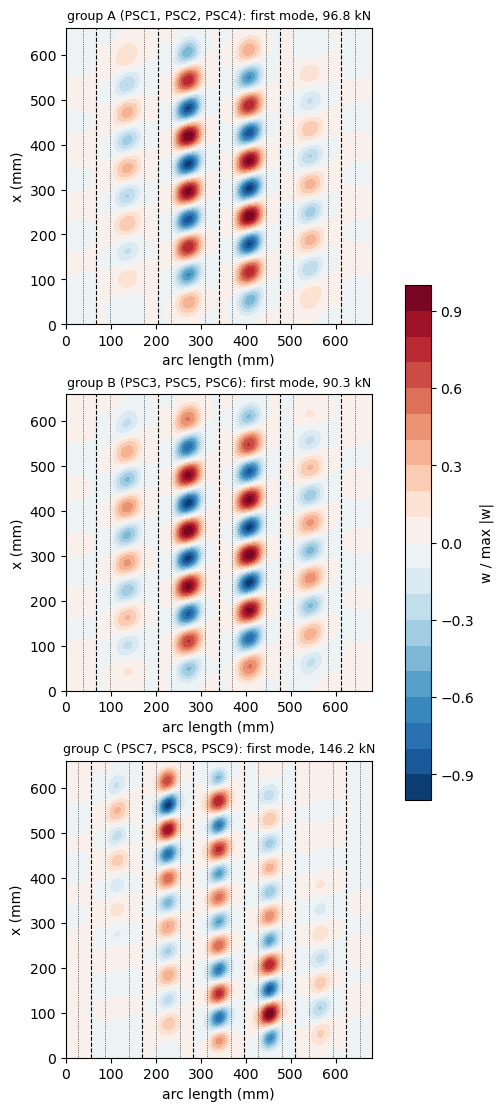

In [6]:
fig, axes = plt.subplots(3, 1, figsize=(8, 11), constrained_layout=True)
for axis, g in zip(axes, GROUPS):
    res = conv[(g, M_FIN, N_FIN)]
    X, S, W = pu.skin_field(res['parts']['skins'], res['evec'][:, 0], gridx=100)
    W = W/np.abs(W).max()
    cs = axis.contourf(S, X, W, levels=np.linspace(-1, 1, 21), cmap='RdBu_r')
    for ys in GROUPS[g]['ys']:
        axis.axvline(ys, color='k', lw=0.8, ls='--')
        for dy in (-30., 30.):
            axis.axvline(ys + dy, color='k', lw=0.5, ls=':')
    axis.set_aspect('equal')
    axis.set_xlabel('arc length (mm)')
    axis.set_ylabel('x (mm)')
    axis.set_title('group %s (%s): first mode, %.1f kN'
                   % (g, GROUPS[g]['panels'], res['crit']), fontsize=9)
fig.colorbar(cs, ax=axes, shrink=0.5, label='w / max |w|')
plt.show()

## 7. Sensitivity

**Ply drops of the feet.** The three schemes of Section 1 (stacks printed in Section 1, from the inner
face of the foot to the skin), for the three groups with the finest mesh of Section 4. The total
thickness of each step is that of the drawing in all of them; they differ in the stiffness of the two
outer steps, the 0° plies giving axial stiffness and the ±45° plies shear and bending stiffness across
the foot.

In [7]:
rows = []
for g, d in GROUPS.items():
    base = conv[(g, M_FIN, N_FIN)]['crit']
    for name, stacks in PLY_DROPS.items():
        if stacks is PLY_DROPS['repeats [45/-45/0/0] dropped']:
            p = base
        else:
            p = solve(g, M_FIN, N_FIN, feet=[(10., st) for st in stacks])['crit']
        rows.append([g, name, '%.1f' % p, '%+.1f' % rel(p, base), '%.0f' % d['nastran'],
                     '%+.1f' % rel(p, d['nastran'])])
print('m = %d, n = %d' % (M_FIN, N_FIN))
print_table(rows, ['group', 'ply drops', 'first buckling (kN)', 'change %',
                   'MSC/NASTRAN [2] (kN)', 'difference %'])

m = 28, n = 14
group                     ply drops  first buckling (kN)  change %  MSC/NASTRAN [2] (kN)  difference %
-----  ----------------------------  -------------------  --------  --------------------  ------------
    A  repeats [45/-45/0/0] dropped                 96.8      +0.0                    92          +5.3
    A     0 deg plies dropped first                 91.9      -5.1                    92          -0.1
    A  +-45 deg plies dropped first                 96.9      +0.1                    92          +5.4
    B  repeats [45/-45/0/0] dropped                 90.3      +0.0                    89          +1.5
    B     0 deg plies dropped first                 85.3      -5.6                    89          -4.2
    B  +-45 deg plies dropped first                 90.9      +0.6                    89          +2.1
    C  repeats [45/-45/0/0] dropped                146.2      +0.0                   139          +5.2
    C     0 deg plies dropped first                140.4  

**Other data and modelling choices.** With the mesh $m = 24$, $n = 12$ of Section 4, for group A:

* the unloaded edges clamped ($w = w_{,y} = 0$) instead of $w = 0$;
* the length 680 mm, the "nominal test length" of [1] (p. 1189), instead of the 660 mm between the
  end loading pieces of the drawing of [2];
* the foot with the mid-surface of the skin as reference surface and the blade standing on it, as in
  the bfsccylinder implementation of this case: the blade domain is then $h_s + 0.5$ mm wide and
  overlaps the skin and the foot;
* the blades as `plate_clpt_donnell` plates, with the von Kármán strains, instead of `plate_clpt_gl`;
* the feet removed, the blades standing on the skin (the blade domain is then measured from the
  mid-surface of the skin, and the widest bay, 136 mm, has $n = 24$), which shows how much the feet
  stiffen the skin.

In [8]:
M_S, N_S = 24, 12
base = conv[('A', M_S, N_S)]['crit']
# without feet the widest bay is 136 mm instead of 76 mm: more terms across it
cases = [('unloaded edges clamped', N_S, dict(unloaded='clamped')),
         ('length 680 mm', N_S, dict(L=680.)),
         ('foot and blade on the skin mid-surface', N_S, dict(foot_reference='skin')),
         ('blades plate_clpt_donnell', N_S, dict(blade_model='plate_clpt_donnell')),
         ('no feet', 24, dict(feet=[]))]
rows = [['model of Sections 2 to 5', '%.1f' % base, '']]
for name, n, kwargs in cases:
    res = solve('A', M_S, n, **kwargs)
    rows.append([name, '%.1f' % res['crit'], '%+.1f' % rel(res['crit'], base)])
print_table(rows, ['group A, m = %d, n = %d' % (M_S, N_S), 'first buckling (kN)', 'change %'])

               group A, m = 24, n = 12  first buckling (kN)  change %
--------------------------------------  -------------------  --------
              model of Sections 2 to 5                 96.8          
                unloaded edges clamped                 96.8      +0.0
                         length 680 mm                 96.9      +0.1
foot and blade on the skin mid-surface                 98.6      +1.8
             blades plate_clpt_donnell                 96.8      +0.0
                               no feet                 49.8     -48.6


## 8. Discussion

**Convergence.** The first buckling load of the three groups changes by less than 0.02 % from $m = 24$
to $m = 28$, and by 0.01 % or less with more terms across the feet and the blades (Section 4). The
warnings printed during the study come from the null-space elimination of the constraints, among them
redundant ones (the supports of the feet at the loaded ends repeat those of the skin, to which the feet
are bonded): the gap between the smallest independent pivot (6.9e-6 or 7.4e-6) and the largest
redundant one (8.7e-10) is narrower than usual but still of nearly four orders of magnitude, and the
loads of all meshes follow the same convergence.

**Finite element model of [2].** The loads of the model agree with the MSC/NASTRAN first buckling loads
of [2] within +1.5 % (group B) to +5.3 % (group A). Both are linear analyses of the perfect panels with
the nominal data; [2] does not describe its mesh, its boundary conditions or its model of the feet.
Both models give the same trends: the 15 mm blades lower the load, by 3 % in [2] and 7 % here, and the
sixth blade raises it, by 51 % in [2] and 51 % here.

**The other implementation.** The bfsccylinder implementation of this case
(`abramovich2003_stiffened_panels`, values of 2026-11-04) gives 98.9, 92.4 and 150.0 kN for groups A, B
and C, 2.1 % to 2.5 % above the loads here. Its blade stands on the mid-surface of the skin; with that
choice (Section 7, group A) this model gives 98.6 kN, 0.3 % below it. The two implementations agree.

**Ply drops of the feet.** Which plies end at the steps of the feet is not given in [1] or [2], and the
three schemes of Section 7 change the load by up to 5.6 %: 91.9 to 96.9 kN for group A, 85.3 to 90.9 kN
for group B and 139.8 to 146.2 kN for group C, that is -0.1 % to +5.4 %, -4.2 % to +2.1 % and +0.6 %
to +5.2 % against MSC/NASTRAN. This range is the uncertainty of the model due to the unknown ply drops;
the data of the papers do not select one of the schemes, and all of them agree with [2] within the
scatter of the comparison. Dropping the 0° plies first gives the lowest loads of groups A and B, and
dropping the ±45° plies first the lowest of group C, so the stiffness that matters depends on the mode.

**Tests.** Both linear analyses are well below the first buckling loads measured on the panels, this
model by 20 % to 40 %, as [2] notes for its own predictions ("the predicted local buckling loads
under-estimated the test results", p. 2), and the three nominally identical panels of each group differ
by up to 21 % (group A: 131.0 to 158.5 kN). The test value is the load at which the first buckle is seen
with the Moiré technique or in the strain gauges ([1], p. 1189; [2], p. 2), which is not the bifurcation
load of a perfect panel; neither [1] nor [2] explains the difference, and the model does not either.

**Mode shapes and sensitivity.** The first mode is a buckling of the skin in the bays between the feet
(Section 6). Accordingly, the support of the unloaded edges and the length, 660 or 680 mm, change the
load by 0.1 % or less, and so does the model of the blades: with the von Kármán strains of
`plate_clpt_donnell` instead of the Green-Lagrange strains the load is the same, since the blades do not
bend in their plane in this mode. The feet, on the contrary, decide the load: without them the bays are
136 mm wide instead of 76 mm and the load drops by 49 %, which is why their ply drops matter.


In [9]:
print('total run time: %.0f min' % ((time.time() - T_START)/60))

total run time: 94 min
